# Online News Popularity: Machine Learning

**Prediction question:** Can an article's content, category, sentiment, and
publication-day characteristics predict whether it will receive at least
**2,800 shares**?

This shared notebook currently implements **logistic regression only**. Random
Forest and Histogram Gradient Boosting have placeholders at the end. The final
comparison of three different model types is still pending.

## Setup and Data

Keep `OnlineNewsPopularity.csv` beside this notebook and run the cells in order.
Install the project's `requirements.txt` in your Python environment first;
the optional cell below is an alternative for installing just the ML libraries.

In [1]:
# Uncomment and run once if needed.
# %pip install pandas numpy matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    make_scorer, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)

df = pd.read_csv("OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()
print(f"Dataset: {df.shape[0]:,} articles and {df.shape[1]} columns")
print(f"Missing values: {df.isna().sum().sum():,}")
print(f"Duplicate article URLs: {df['url'].duplicated().sum():,}")

Dataset: 39,644 articles and 61 columns
Missing values: 0
Duplicate article URLs: 0


## Define the Target and Predictors

- **Popular (1):** at least 2,800 shares; **not popular (0):** fewer than 2,800.
- The cutoff comes from the earlier EDA's approximate upper quartile. We keep it
  fixed here rather than calculating a new cutoff from the test set. Around one
  quarter of articles are popular, so the classes are not balanced.
- The earlier model used article length alone. This version uses 19 original
  features: article/title length, links, media counts, average token length,
  keyword count, sentiment, six category flags, and the weekend flag.
- URL is an identifier, and `timedelta` measures article age after publication.
  Both are excluded. Keyword share statistics and self-reference share counts
  are also excluded because their availability at prediction time is uncertain.
- `shares` creates the target but is never an input. EDA-derived columns such as
  `log_shares` and `is_popular` are not included in the predictor list.

In [3]:
POPULAR_CUTOFF = 2800
RANDOM_STATE = 13

feature_columns = [
    "n_tokens_title", "n_tokens_content", "num_hrefs", "num_self_hrefs",
    "num_imgs", "num_videos", "average_token_length", "num_keywords",
    "global_subjectivity", "global_sentiment_polarity",
    "title_subjectivity", "title_sentiment_polarity",
    "data_channel_is_lifestyle", "data_channel_is_entertainment",
    "data_channel_is_bus", "data_channel_is_socmed",
    "data_channel_is_tech", "data_channel_is_world", "is_weekend",
]
X = df[feature_columns].replace([np.inf, -np.inf], np.nan)
y = (df["shares"] >= POPULAR_CUTOFF).astype(int)
print(f"Predictors: {X.shape[1]}; popular articles: {y.mean():.1%}")

Predictors: 19; popular articles: 25.2%


## Reserve a Test Set

We use an **80% training / 20% test split**. Stratification keeps similar class
proportions in both sets, and a fixed seed makes the results reproducible.
Only training data is used to fit preprocessing and select parameters.

This retains the original notebook's split. An earlier version already reported
a result on that test set, so this is an exploratory course-project evaluation,
not a completely new external validation. Do not use the test results below to
choose parameters or decide between the future model types.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)
split_counts = pd.DataFrame({
    "Train articles": y_train.value_counts(),
    "Test articles": y_test.value_counts(),
}).rename(index={0: "Not popular", 1: "Popular"})
display(split_counts)

majority_class = y_train.mode().iloc[0]
print(f"Training majority-class accuracy: {(y_train == majority_class).mean():.3f}")
print("Always predicting 'not popular' gives popular-class F1 = 0.")

,Train articles,Test articles
shares,,
Not popular,23724,5931
Popular,7991,1998


Training majority-class accuracy: 0.748
Always predicting 'not popular' gives popular-class F1 = 0.


## 1. Logistic Regression

Logistic regression estimates the probability that an article is popular. Its
decision boundary is linear in the input features, making it a useful,
interpretable starting point.

### Preprocessing Pipeline

1. **Median imputation:** handles missing or non-finite numeric inputs. The
   current CSV has no missing values, but this keeps preprocessing explicit.
2. **Standardization:** puts numeric predictors on comparable scales, which
   matters for logistic regression's regularization.
3. **Logistic regression:** learns a binary classifier with L2 regularization.

Imputation and scaling are fitted inside the pipeline on each training fold,
so validation observations do not influence their parameters. Zero article
lengths remain valid numeric observations; they are not treated as missing.

In [5]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

### Five-Fold Cross-Validation and Parameter Selection

We divide the training set into **five stratified folds**. Each configuration is
trained on four folds and validated on the fifth, rotating through all folds.
Every configuration uses the same folds.

We compare `C = 0.1, 1, 10` and `class_weight = None` or `"balanced"`: **six
configurations of the same model type**, not six different ML algorithms.
Smaller `C` means stronger regularization. Balanced weights give the less
frequent class greater influence during fitting; they are calculated from each
training fold.

**Selection metric: popular-class F1**, which balances precision and recall.
Accuracy alone can be misleading when roughly 75% of articles are not popular.
We also report accuracy, precision, recall, and ROC-AUC. Standard deviations show
variation across folds, not confidence intervals. The probability decision
threshold stays at **0.5**; it is not tuned on test data.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}
logistic_search = GridSearchCV(
    logistic_pipeline,
    param_grid={
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=1, error_score="raise",
)
logistic_search.fit(X_train, y_train)

cv_results = pd.DataFrame(logistic_search.cv_results_)
cv_results = cv_results.sort_values("rank_test_f1")
cv_summary = cv_results[["param_classifier__C", "param_classifier__class_weight"]].copy()
cv_summary.columns = ["C", "Class weight"]
cv_summary["Class weight"] = cv_summary["Class weight"].astype(str)
for metric in scoring:
    cv_summary[metric] = [
        f"{mean:.3f} +/- {std:.3f}"
        for mean, std in zip(cv_results[f"mean_test_{metric}"], cv_results[f"std_test_{metric}"])
    ]
display(cv_summary.reset_index(drop=True))
print("Selected parameters:", logistic_search.best_params_)
print(f"Best mean validation F1: {logistic_search.best_score_:.3f}")

,C,Class weight,accuracy,precision,recall,f1,roc_auc
0,0.1,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
1,1.0,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
2,10.0,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
3,10.0,None,0.747 +/- 0.001,0.467 +/- 0.019,0.037 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003
4,1.0,None,0.747 +/- 0.001,0.466 +/- 0.020,0.037 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003
5,0.1,None,0.747 +/- 0.001,0.466 +/- 0.016,0.036 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003


Selected parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best mean validation F1: 0.444


### Compare the Logistic Regression Configurations

The charts compare validation F1 and accuracy for the same configurations.
Error bars show one fold standard deviation. The best accuracy configuration
may differ from the best F1 configuration; our selection rule was fixed as F1
before inspecting these results. If scores are almost tied, the ranking should
not be interpreted as a large or certain improvement.

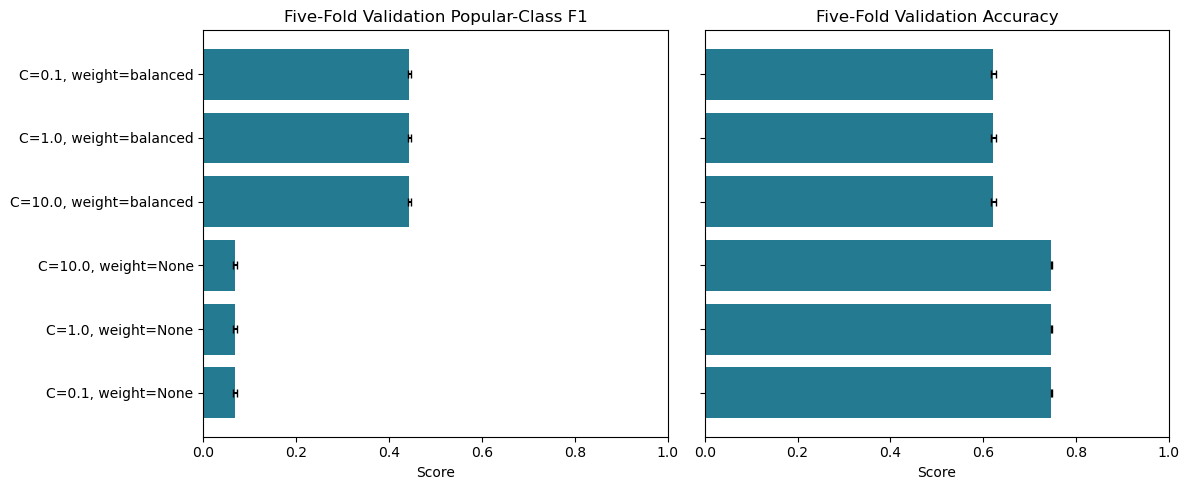

In [7]:
configuration_labels = [
    f"C={row['C']}, weight={row['Class weight']}"
    for _, row in cv_summary.iterrows()
]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for axis, metric, title in zip(axes, ["f1", "accuracy"], ["Popular-Class F1", "Accuracy"]):
    axis.barh(
        configuration_labels, cv_results[f"mean_test_{metric}"],
        xerr=cv_results[f"std_test_{metric}"], capsize=3, color="#247B91",
    )
    axis.set(title=f"Five-Fold Validation {title}", xlabel="Score", xlim=(0, 1))
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()
plt.close()

### Interpret the Logistic Regression Coefficients

`GridSearchCV` refits the selected pipeline on all training data. We inspect
that fitted model without using the test set. A positive coefficient increases
the estimated log-odds of popularity, holding the other modeled features fixed;
a negative coefficient decreases them.

Because all inputs were standardized, each coefficient represents a one-training-
standard-deviation change, not a one-token change or a direct category switch.
Correlated predictors can affect the coefficients. These are model associations,
not causal effects or guaranteed feature importance rankings.

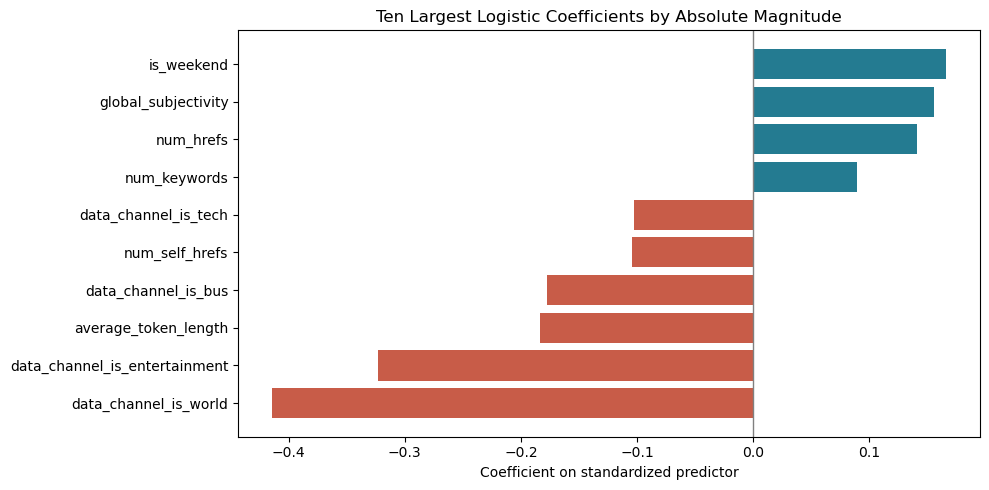

In [8]:
logistic_model = logistic_search.best_estimator_
coefficients = pd.Series(
    logistic_model.named_steps["classifier"].coef_[0], index=feature_columns,
)
largest_coefficients = coefficients.loc[coefficients.abs().nlargest(10).index].sort_values()

plt.figure(figsize=(10, 5))
plt.barh(
    largest_coefficients.index, largest_coefficients.values,
    color=["#247B91" if value > 0 else "#C85C48" for value in largest_coefficients],
)
plt.axvline(0, color="gray", linewidth=1)
plt.title("Ten Largest Logistic Coefficients by Absolute Magnitude")
plt.xlabel("Coefficient on standardized predictor")
plt.tight_layout()
plt.show()
plt.close()

### Evaluate the Selected Logistic Regression on the Test Set

After selecting parameters from training-set cross-validation, we evaluate this
logistic regression pipeline once on the test set. No parameters or thresholds
are changed in response to these scores.

- **Precision:** among predicted-popular articles, how many are actually popular?
- **Recall:** among actually popular articles, how many did the model identify?
- **F1:** the harmonic mean of popular-class precision and recall.
- **ROC-AUC:** how well probabilities rank the classes across thresholds;
  0.5 represents chance ranking.
- **Accuracy:** the fraction of all predictions that are correct, interpreted
  alongside the simple majority-class reference rather than on its own.

The confusion matrix shows error counts at threshold 0.5. Missing popular
articles are false negatives; incorrectly flagging other articles as popular
produces false positives. The ROC curve uses probabilities, not hard labels.

Accuracy     0.625
Precision    0.358
Recall       0.613
F1           0.452
ROC-AUC      0.655
Name: Logistic regression test score, dtype: float64

Majority-class reference test accuracy: 0.748
              precision    recall  f1-score   support

 Not popular       0.83      0.63      0.72      5931
     Popular       0.36      0.61      0.45      1998

    accuracy                           0.63      7929
   macro avg       0.59      0.62      0.58      7929
weighted avg       0.71      0.63      0.65      7929



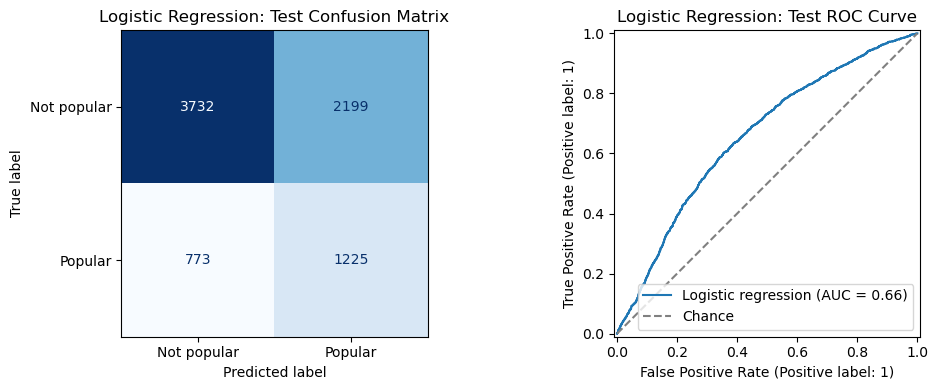

In [9]:
test_predictions = logistic_model.predict(X_test)
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]
logistic_test_scores = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions),
    "F1": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
}, name="Logistic regression test score")
display(logistic_test_scores.round(3))
majority_test_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"Majority-class reference test accuracy: {majority_test_accuracy:.3f}")
print(classification_report(
    y_test, test_predictions, target_names=["Not popular", "Popular"], zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["Not popular", "Popular"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Logistic Regression: Test Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes[1].set_title("Logistic Regression: Test ROC Curve")
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close()

### Logistic Regression Findings and Limitations

The output below answers the prediction question using measured results.
Classification performance is not the same as predicting an exact number of
shares. This model uses a linear boundary, and counts remain right-skewed even
after scaling. Popularity can also depend on factors missing from the dataset.
Results from one publisher and historical articles may not generalize to future
articles or other publishers.

In [10]:
print(f"Selected logistic regression: {logistic_search.best_params_}")
print(f"Mean cross-validation F1: {logistic_search.best_score_:.3f}")
print(f"Test F1: {logistic_test_scores['F1']:.3f}; test ROC-AUC: {logistic_test_scores['ROC-AUC']:.3f}")
print(
    f"At threshold 0.5, {logistic_test_scores['Precision']:.1%} of articles flagged as popular "
    f"were popular, and {logistic_test_scores['Recall']:.1%} of all popular articles were identified."
)
print(
    f"Test accuracy was {logistic_test_scores['Accuracy']:.1%}, compared with "
    f"{majority_test_accuracy:.1%} for always predicting the training majority class. "
    "The selected configuration optimizes validation F1, not accuracy."
)

Selected logistic regression: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Mean cross-validation F1: 0.444
Test F1: 0.452; test ROC-AUC: 0.655
At threshold 0.5, 35.8% of articles flagged as popular were popular, and 61.3% of all popular articles were identified.
Test accuracy was 62.5%, compared with 74.8% for always predicting the training majority class. The selected configuration optimizes validation F1, not accuracy.


## 2. Random Forest

**Placeholder.** Not implemented.

In [11]:
# TODO: Add the random forest pipeline and five-fold training-set evaluation.

## 3. Histogram Gradient Boosting

**Placeholder.** Not implemented.

In [12]:
# TODO: Add the histogram gradient boosting pipeline and five-fold training-set evaluation.

## 4. Final Three-Model Comparison

**Placeholder.** Complete sections 2 and 3 before comparing the three model
types on the same training data and folds. Select the overall winner using
cross-validation F1, report accuracy and the other metrics, and then evaluate
that winner on the test set. Test results must not determine the winner.

The six logistic regression configurations above do **not** satisfy the
assignment's requirement for three different ML model types.

In [13]:
# TODO: Compare the three completed model types and evaluate the selected winner.